In [1]:
import sys
sys.path.append('../')
import numpy as np
import pandas as pd
from exp_utils import CounterPlotNice
from sklearn.ensemble import RandomForestClassifier

In [2]:
# Download wine dataset
! wget https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv

# Read wine dataset
wine = pd.read_csv('winequality-red.csv', sep=';')

X, y = wine.drop('quality', axis=1), wine['quality']

# Transform X to numpy
X  = X.to_numpy()
# Transform y to binary
y = np.where(y > 5, 1, 0)

--2026-02-05 01:16:16--  https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
Loaded CA certificate '/etc/ssl/certs/ca-certificates.crt'
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘winequality-red.csv.4’

winequality-red.csv     [  <=>               ]  82.23K   244KB/s    in 0.3s    

2026-02-05 01:16:18 (244 KB/s) - ‘winequality-red.csv.4’ saved [84199]



In [3]:
# Make RF model for noisy dataset
model = RandomForestClassifier(random_state=42)

In [4]:
model.fit(X, y)

RandomForestClassifier(random_state=42)

In [5]:
exp_nice = CounterPlotNice(
    predict_fn=model.predict_proba,
    X_train=X,
    y_train=y,
    cat_feat=[])

In [ ]:
# Select case with negative countershapley value
counterplot = exp_nice.explain(
    np.array([X[533]])
)[0]

Runtime is dominated by `generate_contribution_graph`, which needs to iterate all subcoalition combinations and run model inference once per combination.

In [264]:
import cProfile, pstats
from counterplots.utils.process import calc_shapley_values_between

def get_function_stats(stats, function_name):
    """Extract pstatsb for a specific function."""
    for func, (primitive_calls, total_calls, total_time, cumulative_time, callers) in stats.stats.items():
        if function_name in func[2]:  # func[2] is the function name
            return {
                'function': func,
                'total_calls': total_calls,
                'primitive_calls': primitive_calls,
                'total_time': total_time,
                'cumulative_time': cumulative_time
            }
    return None

def profile_calc_shapley(f, model, size=1):
    cf = f.copy()
    for i in range(size): cf[i] *= 1.1
    profiler = cProfile.Profile()
    profiler.enable()

    calc_shapley_values_between(
        f, 
        cf,
        model=model.predict_proba
    )

    profiler.disable()
    return pstats.Stats(profiler)

In [265]:
import time

for size in range(11, 12):
    nruns = 100//size  # reasonable sample size
    times, ncalls = [], []
    stats_objects = []
    for run in range(nruns):
        start=time.time()  # simply for output, not for profiling
        
        stats = profile_calc_shapley(  # this is the actual profiles
            counterplot.factual,
            model,
            size=size
        )
        stats_objects.append(stats)
    print(f"Finished benchmarking size {size} after {time.time() - start:.4f} seconds ({nruns} samples)")
    print("Extracting and writing data")
    for stats in stats_objects:
        times.append(get_function_stats(stats, "predict_proba")['total_time'])
        ncalls.append(get_function_stats(stats, "predict_proba")['total_calls'])
    with open(f"benchmarks/size{size}.txt", "w+") as of:
        for t, c in zip(times, ncalls):
            of.write(f"{t}\t{c}\n")
    


Finished benchmarking size 11 after 33.0779 seconds (9 samples)
Extracting and writing data


In [269]:
import os
n_sizes = len(os.listdir('benchmarks'))

In [270]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

dfs = []
for size in range(n_sizes):
    # ncalls never changes, bit silly to have as a column, but oh well
    df = pd.read_csv(
        f"benchmarks/size{size+1}.txt", 
        sep="\t", 
        header=None, 
        names=[f'{size+1}', f'ncalls{size+1}']
        )
    dfs.append(df[f'{size+1}']*1000)  # convert to ms

times = pd.concat(dfs, axis=1)

In [271]:
PINK1 = "#ff0055"
PINK1_TR = "#ff0055d2"
RED1 = "#c20000"
BLUE1 = "#008ae7"
BLUE_TR = "#008ae7d2"
DARK_GREY = "#545454" 
LIGHT_GREY = "#e0e0e0" 

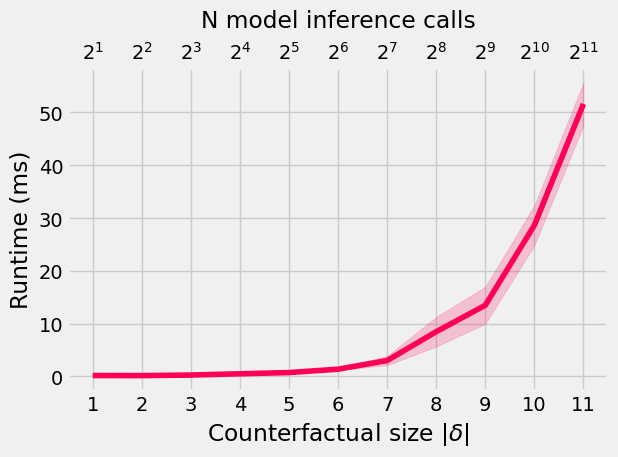

In [295]:
m, s = times.mean(), times.std()

fig, ax1 = plt.subplots()
ax1.plot(m, c=PINK1)
plt.fill_between(
    range(n_sizes),
    m-s, m+s,
    alpha=.2,
    color=PINK1
)

ax2 = ax1.secondary_xaxis('top')
ax2.set_xticks(
    range(n_sizes), 
    [f"$2^{{{k+1}}}$" for k in range(n_sizes)]
)
ax2.set_xlabel('N model inference calls', labelpad=10)
ax1.set_xlabel("Counterfactual size $|\delta|$")
ax1.set_ylabel("Runtime (ms)")

plt.tight_layout()
plt.show()
fig.savefig("perf.png", dpi=300)

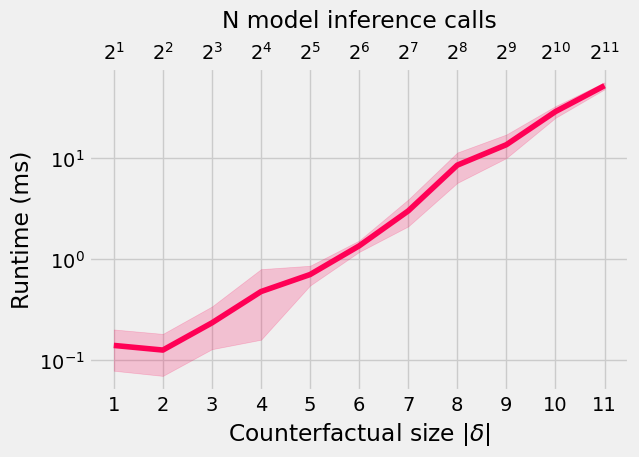

In [297]:
m, s = times.mean(), times.std()

fig, ax1 = plt.subplots()
ax1.plot(m, c=PINK1)
plt.fill_between(
    range(n_sizes),
    m-s, m+s,
    alpha=.2,
    color=PINK1
)

ax2 = ax1.secondary_xaxis('top')
ax2.set_xticks(
    range(n_sizes), 
    [f"$2^{{{k+1}}}$" for k in range(n_sizes)]
)
ax2.set_xlabel('N model inference calls', labelpad=10)
ax1.set_xlabel("Counterfactual size $|\delta|$")
ax1.set_ylabel("Runtime (ms)")

plt.tight_layout()
plt.yscale("log")
fig.savefig("perf_log.png", dpi=300)
plt.show()

For a default random forest classifier, it tenfolds about every increase of 4. So a CFE of size 19 (!!) would take about 5 seconds to calculate the Shapley values for in this case.

For other models, you would have to multiply this value by how much longer inference takes.